Alessia Stefanelli - 615430

# Data Understanding - Dati Tabulari - `vital_sign.csv`

Esplorazione di ciascun dataset, inizialmente, separatamente

### **Informazioni Generali**


In [1]:
# Caricamento librerie necessarie all'analisi dei dataset nei file CSV
import math
import numpy as np
import pandas as pd
import seaborn as sns
import scipy.stats as stats
import matplotlib.pyplot as plt

from collections import defaultdict

import seaborn as sns

from scipy.stats import pearsonr


In [3]:
vital_sign_df = pd.read_csv('../datasets/patients_vital_sign.csv')
patients_df = pd.read_csv('../datasets/patients.csv')

In [3]:
vital_sign_df

,Unnamed: 0,subject_id,stay_id,charttime,temperature,heartrate,resprate,o2sat,sbp,dbp,rhythm,pain
0,0,10000032,32952584,2180-07-22 16:36:00,NaN,83.0,24.0,97.0,90.0,51.0,NaN,0
1,1,10000032,32952584,2180-07-22 16:43:00,NaN,85.0,22.0,98.0,76.0,39.0,NaN,0
2,2,10000032,32952584,2180-07-22 16:45:00,NaN,84.0,22.0,97.0,75.0,39.0,NaN,0
3,3,10000032,32952584,2180-07-22 17:56:00,NaN,84.0,20.0,99.0,86.0,51.0,NaN,NaN
4,4,10000032,32952584,2180-07-22 18:37:00,98.4,86.0,20.0,98.0,65.0,37.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
509210,1564586,19999784,37972930,2119-07-09 22:15:00,98.1,68.0,16.0,100.0,139.0,88.0,NaN,NaN
509211,1564587,19999784,37972930,2119-07-09 23:36:00,97.4,76.0,16.0,99.0,142.0,80.0,NaN,3
509212,1564607,19999987,34731548,2145-11-02 19:40:00,NaN,112.0,18.0,NaN,118.0,83.0,NaN,NaN
509213,1564608,19999987,34731548,2145-11-02 20:11:00,NaN,111.0,18.0,NaN,123.0,82.0,NaN,unable


#### **Osservazione**:  
**Temporary Cleaning** :`Unnamed: 0` dovranno essere rimosse durante la Data Preparation, poiche non hanno un significato apparente

In [4]:
# temp cleaning
vital_sign_df  = vital_sign_df.drop(columns=["Unnamed: 0"])

In [5]:
# num of record and attribute
print("Dim del dataset:", vital_sign_df.shape)

Dim del dataset: (509215, 11)


In [27]:
vital_sign_df.columns

Index(['subject_id', 'stay_id', 'charttime', 'temperature', 'heartrate',
       'resprate', 'o2sat', 'sbp', 'dbp', 'rhythm', 'pain'],
      dtype='object')

In [29]:
# Info sul dataset
vital_sign_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 509215 entries, 0 to 509214
Data columns (total 11 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   subject_id   509215 non-null  int64  
 1   stay_id      509215 non-null  int64  
 2   charttime    509215 non-null  object 
 3   temperature  282646 non-null  float64
 4   heartrate    488234 non-null  float64
 5   resprate     481072 non-null  float64
 6   o2sat        466571 non-null  float64
 7   sbp          483634 non-null  float64
 8   dbp          483634 non-null  float64
 9   rhythm       26023 non-null   object 
 10  pain         363007 non-null  object 
dtypes: float64(6), int64(2), object(3)
memory usage: 42.7+ MB


--- 
### **Dupplicati**

In [14]:
num_duplicates = vital_sign_df.duplicated().sum()
print("Numero di righe duplicate:", num_duplicates)

Numero di righe duplicate: 0


In [15]:
# Trova duplicati basati su una colonna specifica come 'subject_id'
duplicates_subject = vital_sign_df[vital_sign_df.duplicated(subset=['subject_id'])]
print("Numero di duplicati basati su 'subject_id':", len(duplicates_subject))


Numero di duplicati basati su 'subject_id': 468953


In [28]:
# Conta le righe duplicate
# subset_column_num = ['temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp', 'subject_id']
tmp = ['temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp', 'subject_id', 'stay_id']
duplicates = vital_sign_df[vital_sign_df[tmp].duplicated()]
print("Numero di righe duplicate:", len(duplicates))
print("Righe duplicate:")
duplicates


Numero di righe duplicate: 3517
Righe duplicate:


,Unnamed: 0,subject_id,stay_id,charttime,temperature,heartrate,resprate,o2sat,sbp,dbp,rhythm,pain
141,454,10002430,31293660,2125-09-28 22:06:00,98.2,55.0,16.0,100.0,141.0,57.0,NaN,0
191,541,10002807,34934098,2152-03-30 18:54:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
646,1510,10008816,34156352,2130-08-21 07:33:00,97.2,84.0,16.0,98.0,105.0,62.0,NaN,0
672,1536,10008816,35495639,2126-05-22 16:57:00,97.5,86.0,16.0,99.0,130.0,82.0,NaN,0
935,2329,10013502,33522437,2158-10-04 20:53:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...
508796,1563700,19993951,33496052,2139-02-19 09:58:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
508807,1563711,19993951,35934524,2140-06-25 08:23:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3
509034,1564210,19997367,30775693,2126-06-21 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
509101,1564373,19998198,31365518,2122-01-19 17:08:00,97.7,84.0,18.0,99.0,125.0,77.0,NaN,NaN


---

### **Valori Mancanti**

In [16]:
# Controllo che i pazienti siano presenti nel dataset principale 'patients_df'
vital_sign_subject_ids = set(vital_sign_df['subject_id'].unique())
patients_subject_ids = set(patients_df['subject_id'].unique())
missing_subject_ids = vital_sign_subject_ids - patients_subject_ids
num_missing_subject_ids = len(missing_subject_ids)
print(f"Numero di subject_id in vital_sign_df ma non in patient_df: {num_missing_subject_ids}")


Numero di subject_id in vital_sign_df ma non in patient_df: 0


In [31]:
# Conta valori NaN in ogni colonna
print(vital_sign_df.isnull().sum())

subject_id          0
stay_id             0
charttime           0
temperature    226569
heartrate       20981
resprate        28143
o2sat           42644
sbp             25581
dbp             25581
rhythm         483192
pain           146208
dtype: int64


In [52]:
subset_column = ['temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp', 'rhythm', 'pain']

In [34]:
missing_percentage = (vital_sign_df[subset_column].isnull().sum() / len(vital_sign_df)) * 100
print("Percentuale di valori mancanti per ciascuna colonna:")
print(missing_percentage)

Percentuale di valori mancanti per ciascuna colonna:
temperature    44.493780
heartrate       4.120264
resprate        5.526742
o2sat           8.374459
sbp             5.023615
dbp             5.023615
rhythm         94.889585
pain           28.712430
dtype: float64


**Osservazione**: Prendere in considerazione di togliere `rhythm`

In [13]:
# Conta le righe con almeno un valore mancante
rows_any_nan = vital_sign_df[vital_sign_df.isnull().any(axis=1)]
print("Totale righe nel dataset: ", len(vital_sign_df))
print("Totale righe con almeno un NaN: ",  len(rows_any_nan))
print("Numero di righe senza nemmeno un NaN:", len(vital_sign_df) - len(rows_any_nan))
print("Percentuale restanti: ", (len(vital_sign_df) - len(rows_any_nan))/len(vital_sign_df)*100)


Totale righe nel dataset:  509215
Totale righe con almeno un NaN:  500339
Numero di righe senza nemmeno un NaN: 8876
Percentuale restanti:  1.7430751254381747


In [8]:
# Conta le righe interamente vuote
essential_subset_columns = ['temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp']
rows_all_nan = vital_sign_df.dropna(how='all', subset=essential_subset_columns)
print(essential_subset_columns)
print("Numero di righe con tutti NaN per tutte le colonne selezionate:", len(vital_sign_df) - len(rows_all_nan))

['temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp']
Numero di righe con tutti NaN per tutte le colonne selezionate: 8945


In [9]:
# Verifica i valori mancanti per le colonne essenziali, prima e dopo la rimozione dei 8945
tmp_df = vital_sign_df.dropna(how='all', subset=essential_subset_columns)

tmp_df[essential_subset_columns].isnull().sum()
print("Valori mancanti per le colonne essenziali PRIMA della rimozione:")
print(vital_sign_df[essential_subset_columns].isnull().sum())
print("-"*50, "\n")
print("Valori mancanti per le colonne essenziali DOPO la rimozione:")
print(tmp_df[essential_subset_columns].isnull().sum())
print(len(tmp_df))
print("Percentuale restanti: ", len(tmp_df)/len(vital_sign_df)*100)


Valori mancanti per le colonne essenziali PRIMA della rimozione:
temperature    226569
heartrate       20981
resprate        28143
o2sat           42644
sbp             25581
dbp             25581
dtype: int64
-------------------------------------------------- 

Valori mancanti per le colonne essenziali DOPO la rimozione:
temperature    217624
heartrate       12036
resprate        19198
o2sat           33699
sbp             16636
dbp             16636
dtype: int64
500270
Percentuale restanti:  98.24337460601122


In [10]:
# Rimozione totale di NaN
tmp_df_all_na = vital_sign_df[essential_subset_columns].dropna()
print(len(tmp_df_all_na))
print("Percentuale restanti: ", len(tmp_df_all_na)/len(vital_sign_df)*100)

263365
Percentuale restanti:  51.71980401205778


---

### **Statistiche Descrittive + Distribuzione + Analisi outlier**

In [47]:
vital_sign_df.dtypes

subject_id       int64
stay_id          int64
charttime       object
temperature    float64
heartrate      float64
resprate       float64
o2sat          float64
sbp            float64
dbp            float64
rhythm          object
pain            object
dtype: object

In [50]:
obj_column = ['rhythm', 'pain', 'charttime']
for column in obj_column:
    print(f"\nValori unici per [{column}]\n")
    print(vital_sign_df[column].unique())
    print("-"*50, "\n")


Valori unici per [rhythm]

[nan 'Sinus Bradycardia' 'Atrial Fibrillation' 'Sinus Rhythm'
 'Normal Sinus Rhythm' 'afib' 'sr' 'Paced Rhythm' 'refusing'
 'Rapid atrial fibrillation' 'Sinus Tachycardia' 'SB' 'PSVT' 'ST'
 '1&deg; AV Block' 'Sinus Arrythmia' 'nsr' 'normal sinus' 'ns' 'AF' 'Afib'
 'raf' 'st' 'sinus' 'SR' 'atrial fib' 'A Flutter' 'a flutter' 'aflutter'
 'Atrial Flutter' 'Sinus Rhythm with single PVCs' 'reg' 'no' 'af' '`'
 'NSR' 'sb' 'SR, no ect' 'aflutter ' 'sinus rhythm with PVCs' ' ' 'paced'
 'sr with BBB' 'right bundle ' 'Junctional Rhythm' 'r/a' '1Â° AV Block'
 '1&deg; AV Block99' 'vpaced' 'v-paced' 'NSR with 1st degree AV block'
 'NSR with PACs, 1st degree AV block' 'nsr no ectopy' 'Nsr' 'normal'
 'Sinus Rhythm w/ pvcs' 'sinus brady' 'junctional' 'av paced' 'a paced'
 'PAC' 'Sinus Rhythm with PVCs' 'Aflutter' 'SR/PVCs' 'SR w PVCs'
 'frequent PACs- MD aware' 'RB' 'sinus/left bbb'
 'Sinus Rhythm/Sinus Tachycardia' 'Afib ' '\t' 'VPaced' 'Vpaced'
 'Bigeminy' 'Normal Sinus Rh

In [8]:
# Statistiche per ogni NUMERICAL column per determinare anomalie
subset_column_num = ['temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp']
print(vital_sign_df[subset_column_num].describe())

         temperature      heartrate       resprate          o2sat  \
count  282646.000000  488234.000000  481072.000000  466571.000000   
mean       97.779750      82.169195      18.038194      97.679834   
std         8.591832      19.237768       4.434938      14.751942   
min         0.000000       0.000000       0.000000       0.000000   
25%        97.800000      69.000000      16.000000      96.000000   
50%        98.100000      80.000000      18.000000      98.000000   
75%        98.500000      93.000000      19.000000     100.000000   
max       987.000000     705.000000    1796.500000    9712.000000   

                 sbp            dbp  
count  483634.000000  483634.000000  
mean      128.885891      73.306378  
std        24.164182     173.396348  
min         0.000000       0.000000  
25%       112.000000      61.000000  
50%       127.000000      71.000000  
75%       143.000000      82.000000  
max       461.000000   97100.000000  


**Osservazione**: Gli Outlier usare media, mediana o altri valori specifici appropriati. Oppure direttamente cancellarli


In [54]:
# Calcola il range delle colonne numeriche
print("Range per ciascuna variabile numerica :")
for column in subset_column_num:
    print(f"- {column}: MIN: [", vital_sign_df[column].min(),"]       MAX: [",  vital_sign_df[column].max(), ']')


Range per ciascuna variabile numerica :
- temperature: MIN: [ 0.0 ]       MAX: [ 987.0 ]
- heartrate: MIN: [ 0.0 ]       MAX: [ 705.0 ]
- resprate: MIN: [ 0.0 ]       MAX: [ 1796.5 ]
- o2sat: MIN: [ 0.0 ]       MAX: [ 9712.0 ]
- sbp: MIN: [ 0.0 ]       MAX: [ 461.0 ]
- dbp: MIN: [ 0.0 ]       MAX: [ 97100.0 ]


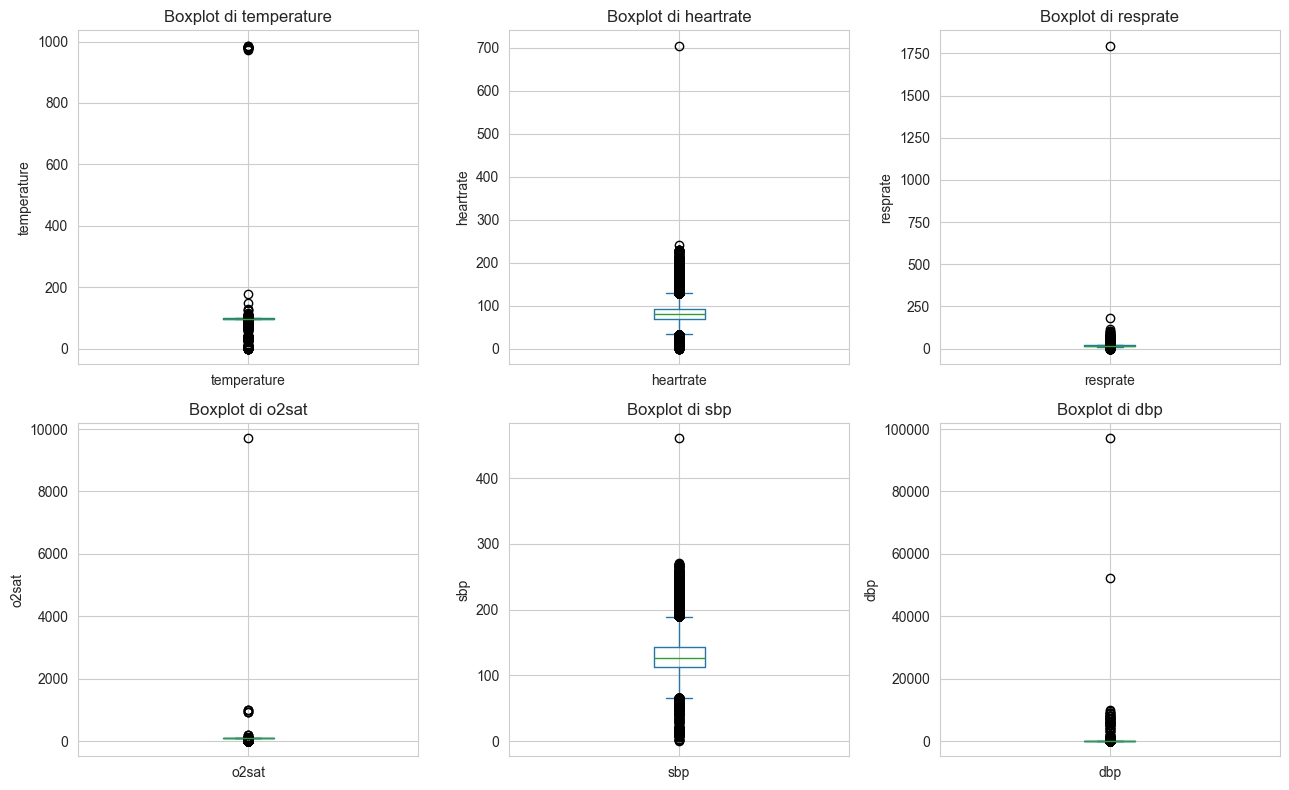

In [17]:
columns = ['temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp']
n_cols = 3
n_rows = 2
fig, axes = plt.subplots(n_rows, n_cols, figsize=(13, 4 * n_rows))
for idx, col in enumerate(columns):
    row = idx // n_cols
    col_idx = idx % n_cols
    ax = axes[row, col_idx]
    vital_sign_df[col].plot(kind='box', ax=ax, title=f'Boxplot di {col}')
    ax.set_ylabel(col)
for i in range(len(columns), n_rows * n_cols):
    fig.delaxes(axes.flat[i])
plt.tight_layout()
plt.show()


---
**Osservazione**: i valori normali dei seguenti attributi devono essere tra:
- `temperature`:  \
    $\text{Se } X \notin [82, 105.8] \Rightarrow X \text{ è un outlier}$
	- Ipotermia severa: Inferiore a 82,4°F (28 °C)  
	- Ipotermia moderata: 82,4°F – 95°F (28-35 °C)  
	- Normale : 96.8 °F – 99.5 °F (36–37.5 °C)  
	- Febbre : 99.5 °F - 105.8°F  (37.5-41 °C)
	- Iperpiressia severa: Oltre 105.8°F (41 °C)

In [18]:
acceptable = vital_sign_df[(vital_sign_df['temperature'] >= 82) & (vital_sign_df['temperature'] <= 105.8)]
df_non_null = vital_sign_df[vital_sign_df['temperature'].notna()]
print("Numero di righe con temperatura accettale (82-105.8°F):", len(acceptable))
print("Num outlier :", len(df_non_null) - len(acceptable))

Numero di righe con temperatura accettale (82-105.8°F): 280361
Num outlier : 2285


---
- `heartrate`:  
    $\text{Se } X \notin [40, 220] \Rightarrow X \text{ è un outlier}$
	- bradicardia severa : inferiore a 40 bpm  
	- low heartrate : 40-60 bpm
	- normale (a risposo): 60-100 bpm   
	- high heartrate : 100-220 bpm
	- tachicardia severa : superiore a 220 bpm

In [19]:
acceptable = vital_sign_df[(vital_sign_df['heartrate'] >= 40) & (vital_sign_df['heartrate'] <= 220)]
print("Numero di righe con heartrate accettale (40-220 bpm):", len(acceptable))
df_non_null = vital_sign_df[vital_sign_df['heartrate'].notna()]
print("Num outlier :", len(df_non_null) - len(acceptable))

Numero di righe con heartrate accettale (40-220 bpm): 486570
Num outlier : 1664


---
- `resprate`:
     $\text{Se } X \notin [8, 35] \Rightarrow X \text{ è un outlier}$
	- Bradipnea severa : inferiore a 7 atti/min  
	- low resprate : 8-12 atti/min
	- normale : 12-20 atti/min   
	- high resprate : 20-35 atti/min
	- tachipnea severa : superiore a 35 atti/min

In [20]:
acceptable = vital_sign_df[(vital_sign_df['resprate'] >= 8) & (vital_sign_df['resprate'] <= 35)]
print("Numero di righe con resprate accettabile (8-35 atti):", len(acceptable))
df_non_null = vital_sign_df[vital_sign_df['resprate'].notna()]
print("Num outlier :", len(df_non_null) - len(acceptable))

Numero di righe con resprate accettabile (8-35 atti): 479001
Num outlier : 2071


--- 
- `o2sat`:
  - dato non valido : superiore a 100 %  
  - normale : 95-100 %
  - low o2sat : 90-95 %
  - o2sat critico: 70-90 %
  - hypoxia severa: inferiore a 70 %

In [21]:
acceptable = vital_sign_df[(vital_sign_df['o2sat'] >= 70) & (vital_sign_df['o2sat'] <= 100)]
print("Numero di righe con o2sat accettabile (70-100 atti):", len(acceptable))
df_non_null = vital_sign_df[vital_sign_df['o2sat'].notna()]
print("Num outlier :", len(df_non_null) - len(acceptable))

Numero di righe con o2sat accettabile (70-100 atti): 466146
Num outlier : 425


--- 
- `sbp`: 
    - crisi ipertensive: superiore a 180 mmHg
    - normale: tra 90 e 120 mmHg
    - insufficienza cardiaca acuta: inferiore a 70 mmHg

In [22]:
acceptable = vital_sign_df[(vital_sign_df['sbp'] >= 70) & (vital_sign_df['sbp'] <= 180)]
print("Numero di righe con sbp accettabile (70-180 atti):", len(acceptable))
df_non_null = vital_sign_df[vital_sign_df['sbp'].notna()]
print("Num outlier :", len(df_non_null) - len(acceptable))

Numero di righe con sbp accettabile (70-180 atti): 468431
Num outlier : 15203


- `dbp`:
    - crisi ipertensive: superiore a 120 mmHg
    - normale: tra 60 e 80 mmHg
    - insufficienza cardiaca acuta: 40 mmHg

In [23]:
acceptable = vital_sign_df[(vital_sign_df['dbp'] >= 40) & (vital_sign_df['dbp'] <= 120)]
print("Numero di righe con dbp accettabile (40-120 atti):", len(acceptable))
df_non_null = vital_sign_df[vital_sign_df['dbp'].notna()]
print("Num outlier :", len(df_non_null) - len(acceptable))

Numero di righe con dbp accettabile (40-120 atti): 476439
Num outlier : 7195


In [24]:
outlier = [(tmp_df_all_na['resprate'] < 8) | (tmp_df_all_na['resprate'] > 35) | (tmp_df_all_na['temperature'] < 82) | (tmp_df_all_na['temperature'] > 105.8) | (tmp_df_all_na['heartrate'] < 40) | (tmp_df_all_na['heartrate'] > 220) | (tmp_df_all_na['o2sat'] < 70) | (tmp_df_all_na['o2sat'] > 100) | (tmp_df_all_na['sbp'] < 70) | (tmp_df_all_na['sbp'] > 180) | (tmp_df_all_na['dbp'] < 40) | (tmp_df_all_na['dbp'] > 120)]
print("Numero di righe non accettabili :", len(outlier))
print("Num accettabile :", len(tmp_df_all_na) - len(outlier))
print("Dataset totale di triage privo di NaN", len(tmp_df_all_na))
print("Percentuale restanti sul dataset triage.csv privo di NaN: ", (len(tmp_df_all_na) - len(outlier))/len(vital_sign_df)*100)
# outlier


Numero di righe non accettabili : 1
Num accettabile : 263364
Dataset totale di triage privo di NaN 263365
Percentuale restanti sul dataset triage.csv privo di NaN:  51.71960763135415


In [25]:
tot_accettabile = vital_sign_df[(vital_sign_df['resprate'] < 8) | (vital_sign_df['resprate'] > 40) | (vital_sign_df['temperature'] < 82) | (vital_sign_df['temperature'] > 105.8) | (vital_sign_df['heartrate'] < 40) | (vital_sign_df['heartrate'] > 220) | (vital_sign_df['o2sat'] < 80) | (vital_sign_df['o2sat'] > 100) | (vital_sign_df['sbp'] < 70) | (vital_sign_df['sbp'] > 180) | (vital_sign_df['dbp'] < 40) | (vital_sign_df['dbp'] > 120)]
print("Numero di righe non accettabili nel dataset originale:", len(tot_accettabile))



Numero di righe non accettabili nel dataset originale: 25560


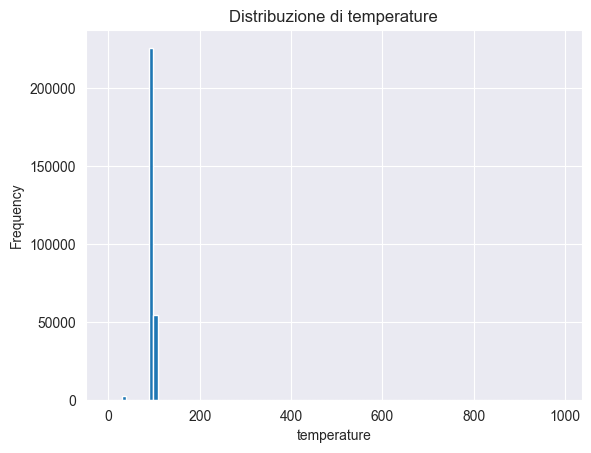

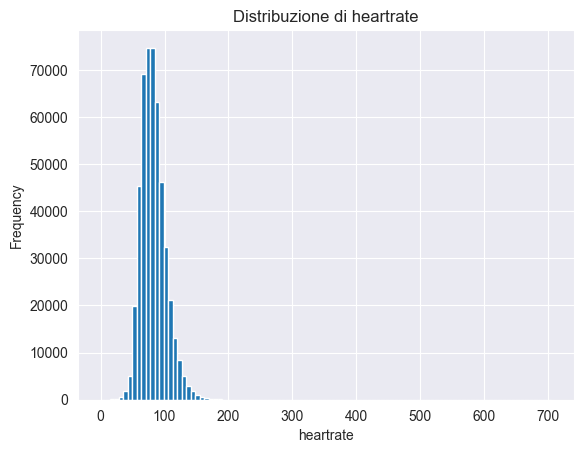

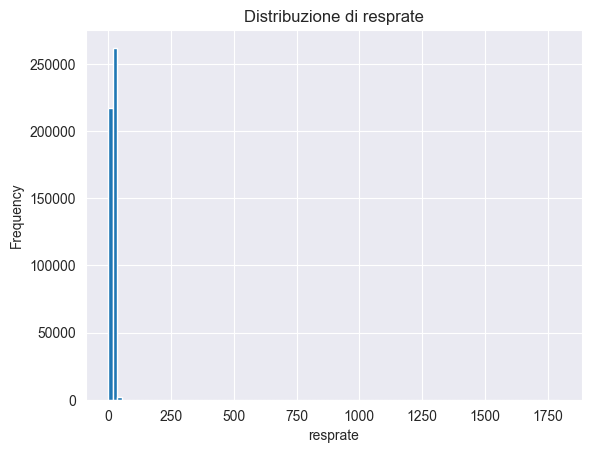

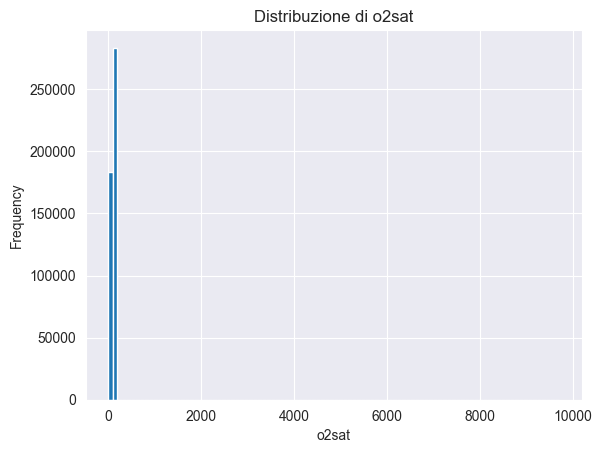

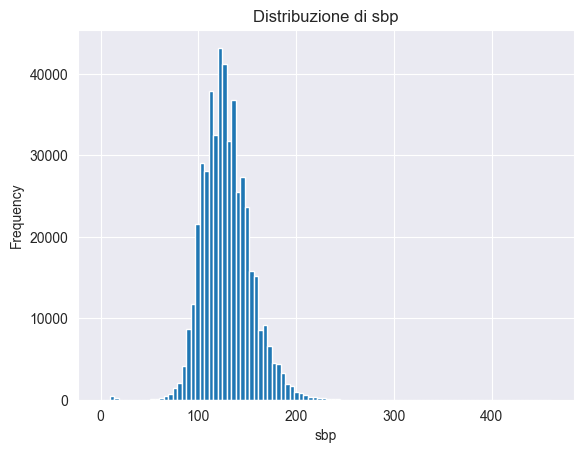

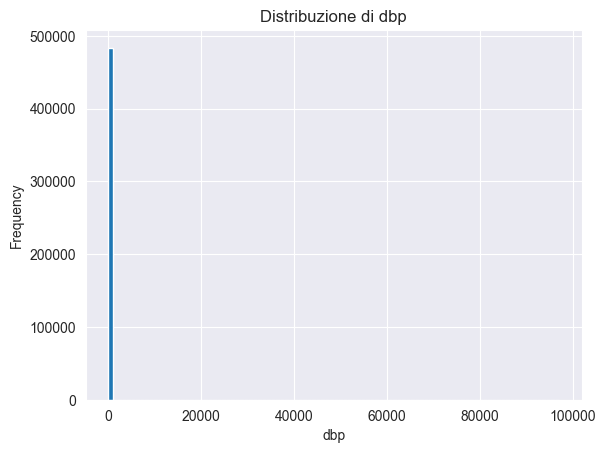

In [65]:
# Istogrammi per le variabili numeriche
for col in subset_column_num:
    plt.figure()
    vital_sign_df[col].plot(kind='hist', bins=100, title=f'Distribuzione di {col}')
    plt.xlabel(col)
    plt.show()


---
### **Valori Unici e Distribuzione Categoriale**

In [71]:
# Visualizza i tipi di dati per identificare le colonne categoriali
print("Tipi di dati nel dataset:")
print(vital_sign_df.dtypes)
print(vital_sign_df.columns)

Tipi di dati nel dataset:
subject_id       int64
stay_id          int64
charttime       object
temperature    float64
heartrate      float64
resprate       float64
o2sat          float64
sbp            float64
dbp            float64
rhythm          object
pain            object
dtype: object
Index(['subject_id', 'stay_id', 'charttime', 'temperature', 'heartrate',
       'resprate', 'o2sat', 'sbp', 'dbp', 'rhythm', 'pain'],
      dtype='object')


In [75]:
sub_column_categorical = ['pain', 'rhythm']
print(vital_sign_df[sub_column_categorical][:20])

      pain rhythm
0        0    NaN
1        0    NaN
2        0    NaN
3      NaN    NaN
4      NaN    NaN
5        0    NaN
6        0    NaN
7        0    NaN
8      NaN    NaN
9      NaN    NaN
10       5    NaN
11     NaN    NaN
12  asleep    NaN
13  unable    NaN
14     uta    NaN
15  unable    NaN
16     uta    NaN
17     uta    NaN
18     uta    NaN
19       u    NaN


In [76]:
for col in sub_column_categorical:
    unique_count = vital_sign_df[col].nunique()
    print(f"Numero di valori unici in '{col}':", unique_count)


Numero di valori unici in 'pain': 1581
Numero di valori unici in 'rhythm': 597


In [77]:
for column in sub_column_categorical:
    print(f"\t\t======= UNIQUE VALUE in [{column}] =======\n")
    print(vital_sign_df[column].unique())
    print("\n\t\t=== Frequency of unique value ===\n")
    print(vital_sign_df[column].value_counts())
    print("-" * 60, "\n")


		======= UNIQUE VALUE in [pain] =======

['0' nan '5' ... '2nd blood' 'refuses' 'refuswed to answer']

		=== Frequency of unique value ===

pain
0                      200623
5                       16467
8                       15066
4                       13276
2                       12419
                        ...  
30                          1
unable to determine         1
all over                    1
Intub.                      1
refuswed to answer          1
Name: count, Length: 1581, dtype: int64
------------------------------------------------------------ 

		======= UNIQUE VALUE in [rhythm] =======

[nan 'Sinus Bradycardia' 'Atrial Fibrillation' 'Sinus Rhythm'
 'Normal Sinus Rhythm' 'afib' 'sr' 'Paced Rhythm' 'refusing'
 'Rapid atrial fibrillation' 'Sinus Tachycardia' 'SB' 'PSVT' 'ST'
 '1&deg; AV Block' 'Sinus Arrythmia' 'nsr' 'normal sinus' 'ns' 'AF' 'Afib'
 'raf' 'st' 'sinus' 'SR' 'atrial fib' 'A Flutter' 'a flutter' 'aflutter'
 'Atrial Flutter' 'Sinus Rhythm with sin

In [99]:
# Conta i valori mancanti nelle colonne categoriali
for column in ['pain']:
    missing_values = vital_sign_df[column].isnull().sum()  
    non_missing_values = vital_sign_df[column].notna().sum()  
    print(f"Colonna: {column} | Num missing: {missing_values} | Num OK: {non_missing_values}")
    print("Lunghezza dataset: ", len(vital_sign_df))


Colonna: pain | Num missing: 146208 | Num OK: 363007
Lunghezza dataset:  509215


**Osservazione**: semantic cleaning: es. 'unaable', 'unablw', 'unbale', 'unqle'
- possible cleaning:
    - upper case -> lower case ('UNABLE' or 'Unable' -> 'unable')
    - strip space (es. ' 4' -> '4')
    - similarity (es. 'unaable' -> 'unable)
    - caratteri speciali e punteggiatura
    - correzione ortografica
    - stemming

---
### **Matrix correlation**


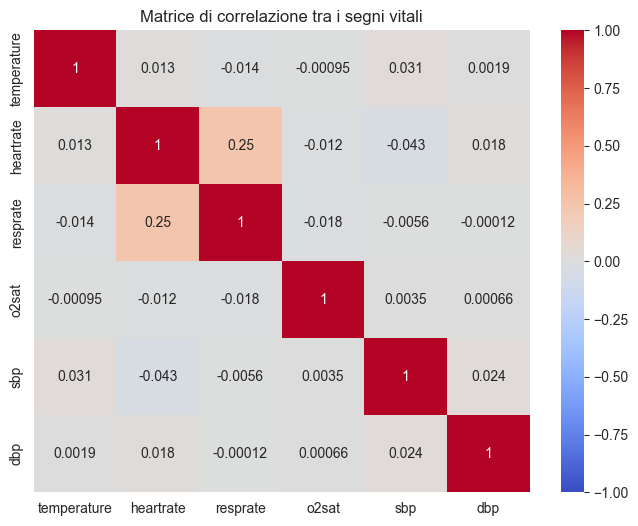

In [89]:
correlation_matrix = vital_sign_df[subset_column_num].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Matrice di correlazione tra i segni vitali")
plt.show()
